# Quanta ECG Examples

Quanta provided us with some signals sampled at 100 Hz. We resampled those
recordings to 256 Hz. This notebook inspects the paired recordings, validates
their 12-bit ADC values, plot the signals in millivolts, and check a lossless
ADC -> mV -> ADC round-trip.

The notebook then runs TinyAF-S/M/L and compare Python, reference C, and
optimized C on the same 256 Hz ADC inputs.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

%matplotlib inline

# Find this checkout without depending on where the notebook server was launched.
root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "python_model" / "runtime.py").is_file()
     and (path / "scripts" / "run_quanta_examples.py").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Open this notebook from the tinyaf checkout.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from scripts.resample_quanta_examples import load_quanta_ecg
from scripts.run_quanta_examples import load_examples
from src.run_example import predict_python, predict_c
from python_model.runtime import MODELS as MODEL_SPECS, TINYAF_MODELS

plt.rcParams["figure.dpi"] = 120
print(f"Repository: {root}")
print(f"Python: {sys.executable}")

Repository: /home/zberger/tinyaf
Python: /home/zberger/miniforge3/envs/tinyaf-research/bin/python


## Select examples and models

We provide two sets of examples: `quanta-examples` and `simulated-afib-examples`.
Use `EXAMPLE_NAMES = None` for all examples in the set, or supply names without
`.txt`.

The implementations are `python`, `reference` (C with float64 preprocessing),
and `optimized` (C with float32 preprocessing). All use float32 neural-network
calculations. Selecting C builds only the requested model/implementation pairs.

In [2]:
EXAMPLE_SET = "quanta-examples"  # Or the other bundled example set.
EXAMPLE_NAMES = None  # Or, for example, ("afib", "sinus-80").
MODELS = TINYAF_MODELS  # Or ("TINYAF-S",) for TinyAF-S only.
IMPLEMENTATIONS = ("python", "reference", "optimized")  # Or ("python",).

SOURCE_RATE_HZ = 100
TARGET_RATE_HZ = 256
DURATION_SECONDS = 10
SOURCE_SAMPLE_COUNT = SOURCE_RATE_HZ * DURATION_SECONDS
TARGET_SAMPLE_COUNT = TARGET_RATE_HZ * DURATION_SECONDS
ADC_LSB_UV = 3.0303
ADC_TO_MV = ADC_LSB_UV / 1000.0

if EXAMPLE_SET not in {"quanta-examples", "simulated-afib-examples"}:
    raise ValueError("Choose one of the two bundled example sets.")
if not MODELS or not set(MODELS) <= set(TINYAF_MODELS):
    raise ValueError("MODELS must select TINYAF-S, TINYAF-M, and/or TINYAF-L.")
if not IMPLEMENTATIONS or not set(IMPLEMENTATIONS) <= {"python", "reference", "optimized"}:
    raise ValueError("Select python, reference, and/or optimized.")
if len(set(MODELS)) != len(MODELS) or len(set(IMPLEMENTATIONS)) != len(IMPLEMENTATIONS):
    raise ValueError("Select each model and implementation at most once.")

## Load and validate raw ECGs

The shared loaders check that each recording is one-dimensional, contains exactly
ten seconds of samples, and has unsigned 12-bit ADC counts in `0..4095`.
The source and resampled directories must contain matching example names.
The arrays below remain available for further exploration in subsequent cells.

In [3]:
example_root = root / "data" / EXAMPLE_SET
source_dir = example_root / "100hz"
target_dir = example_root / "256hz"
if not source_dir.is_dir() or not target_dir.is_dir():
    raise FileNotFoundError(f"Expected 100hz/ and 256hz/ under {example_root}")

ecgs_adc_100hz = {
    path.stem: load_quanta_ecg(path).astype(np.uint16)
    for path in sorted(source_dir.glob("*.txt"))
}
ecgs_adc_256hz = {
    example["name"]: example["adc"] for example in load_examples(target_dir)
}
if ecgs_adc_100hz.keys() != ecgs_adc_256hz.keys():
    raise ValueError("The 100 Hz and 256 Hz directories must contain matching example names.")

names = list(ecgs_adc_256hz) if EXAMPLE_NAMES is None else list(EXAMPLE_NAMES)
if not names or len(set(names)) != len(names):
    raise ValueError("Select at least one example, with no repeated names.")
unknown = set(names) - ecgs_adc_256hz.keys()
if unknown:
    raise ValueError(f"Unknown examples: {sorted(unknown)}. Available: {list(ecgs_adc_256hz)}")
ecgs_adc_100hz = {name: ecgs_adc_100hz[name] for name in names}
ecgs_adc_256hz = {name: ecgs_adc_256hz[name] for name in names}

print(f"Loaded {len(names)} paired examples from {example_root}")
display(pd.DataFrame([
    {
        "example": name,
        "100 Hz samples": len(ecgs_adc_100hz[name]),
        "256 Hz samples": len(ecgs_adc_256hz[name]),
        "100 Hz ADC min": int(ecgs_adc_100hz[name].min()),
        "100 Hz ADC max": int(ecgs_adc_100hz[name].max()),
        "256 Hz ADC min": int(ecgs_adc_256hz[name].min()),
        "256 Hz ADC max": int(ecgs_adc_256hz[name].max()),
    }
    for name in names
]).set_index("example"))

Loaded 5 paired examples from /home/zberger/tinyaf/data/quanta-examples


,100 Hz samples,256 Hz samples,100 Hz ADC min,100 Hz ADC max,256 Hz ADC min,256 Hz ADC max
example,,,,,,
afib,1000,2560,1994,2314,1995,2314
afl-pure,1000,2560,1977,2296,1980,2295
afl,1000,2560,1972,2303,1974,2305
sinus-120,1000,2560,1971,2299,1962,2300
sinus-80,1000,2560,1977,2304,1977,2302


## 100 Hz source vs 256 Hz resampled overlay

These are the original recordings and their stored resampled versions. The model
will receive the 256 Hz ADC arrays. This comparison does not resample or overwrite
any data files.

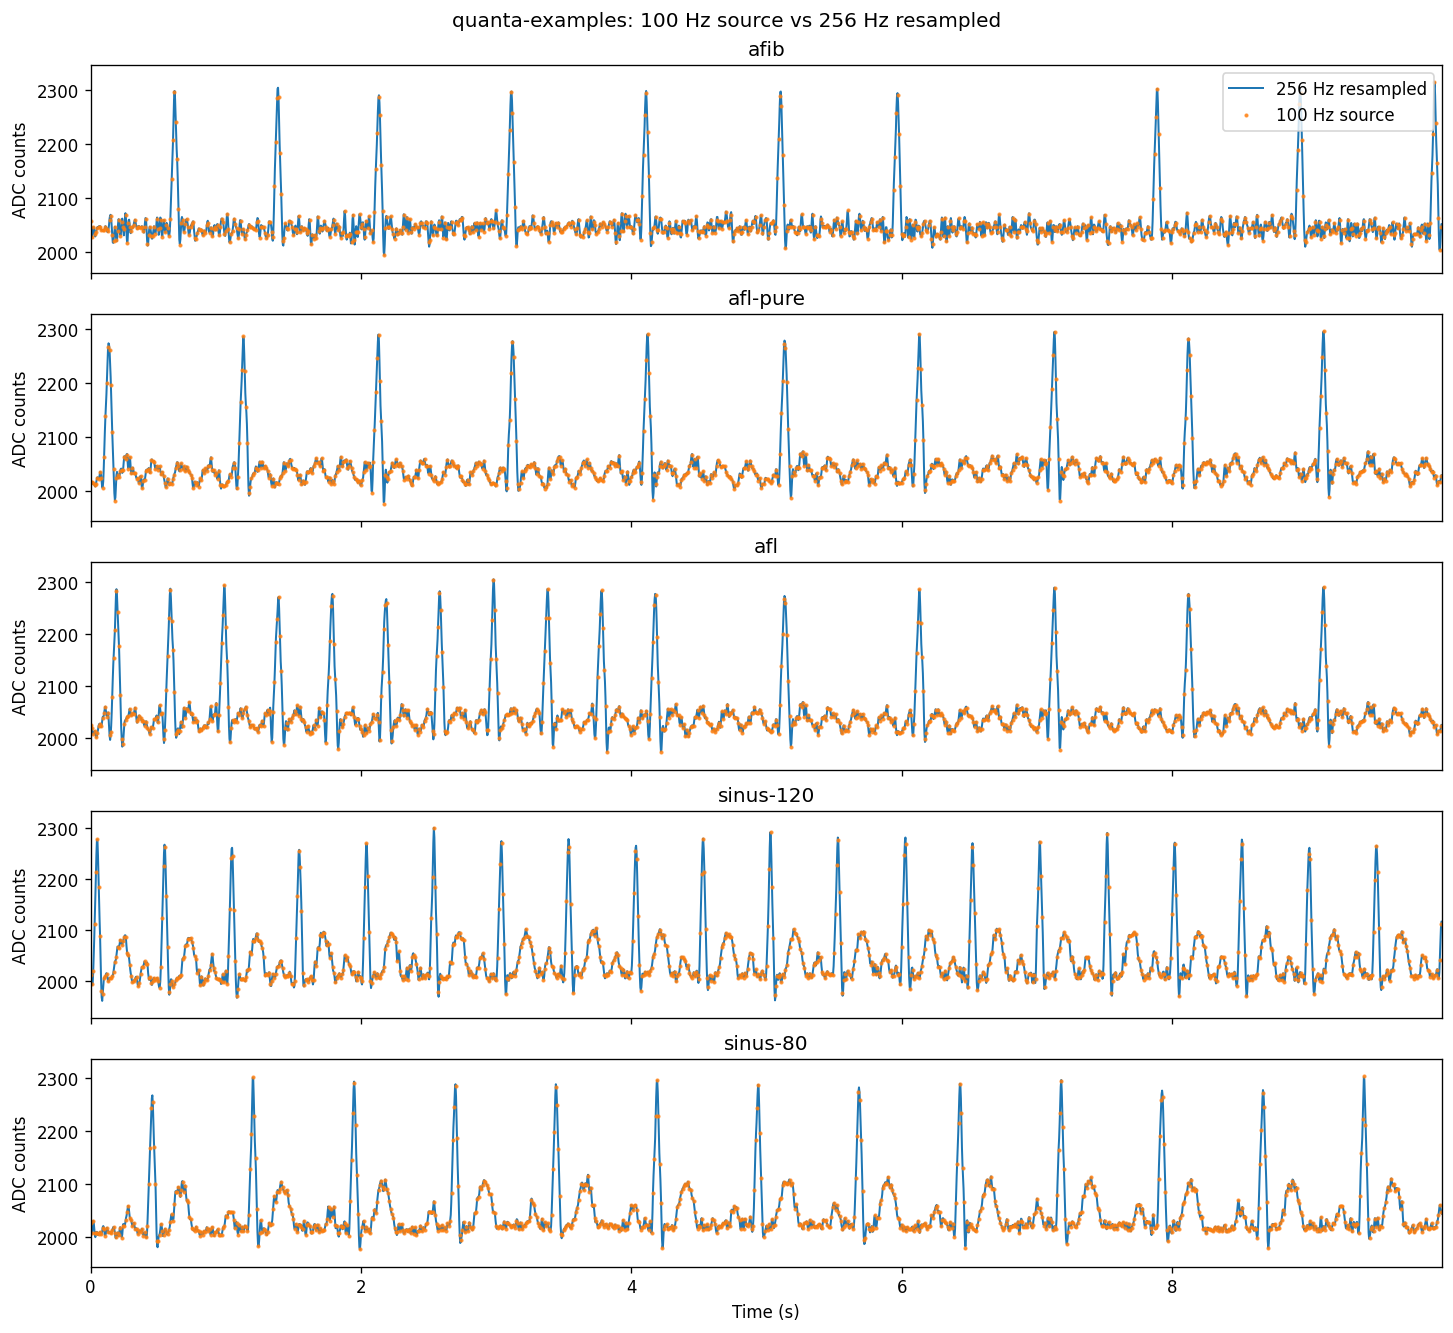

In [4]:
time_100hz_s = np.arange(SOURCE_SAMPLE_COUNT) / SOURCE_RATE_HZ
time_256hz_s = np.arange(TARGET_SAMPLE_COUNT) / TARGET_RATE_HZ

fig, axes = plt.subplots(
    len(names), 1, figsize=(12, 2.2 * len(names)),
    sharex=True, constrained_layout=True,
)
axes = np.atleast_1d(axes)
for ax, name in zip(axes, names):
    ax.plot(time_256hz_s, ecgs_adc_256hz[name], linewidth=1.2, label="256 Hz resampled")
    ax.plot(
        time_100hz_s, ecgs_adc_100hz[name], linestyle="none", marker=".",
        markersize=3, alpha=0.75, label="100 Hz source",
    )
    ax.set_title(name)
    ax.set_ylabel("ADC counts")
    ax.margins(x=0, y=0.1)
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("Time (s)")
fig.suptitle(f"{EXAMPLE_SET}: 100 Hz source vs 256 Hz resampled")
plt.show()

## Convert ADC counts to millivolts

One ADC count is 3.0303 µV, so `ECG (mV) = ADC count × 0.0030303`. These plots
retain the ADC baseline; filtering and DC removal happen later inside model
preprocessing.

In [5]:
ecgs_mv = {
    name: adc.astype(np.float64) * ADC_TO_MV
    for name, adc in ecgs_adc_256hz.items()
}
print(f"ADC LSB = {ADC_LSB_UV} µV/count")
print(f"ECG (mV) = ADC count × {ADC_TO_MV:.7f}")

ADC LSB = 3.0303 µV/count
ECG (mV) = ADC count × 0.0030303


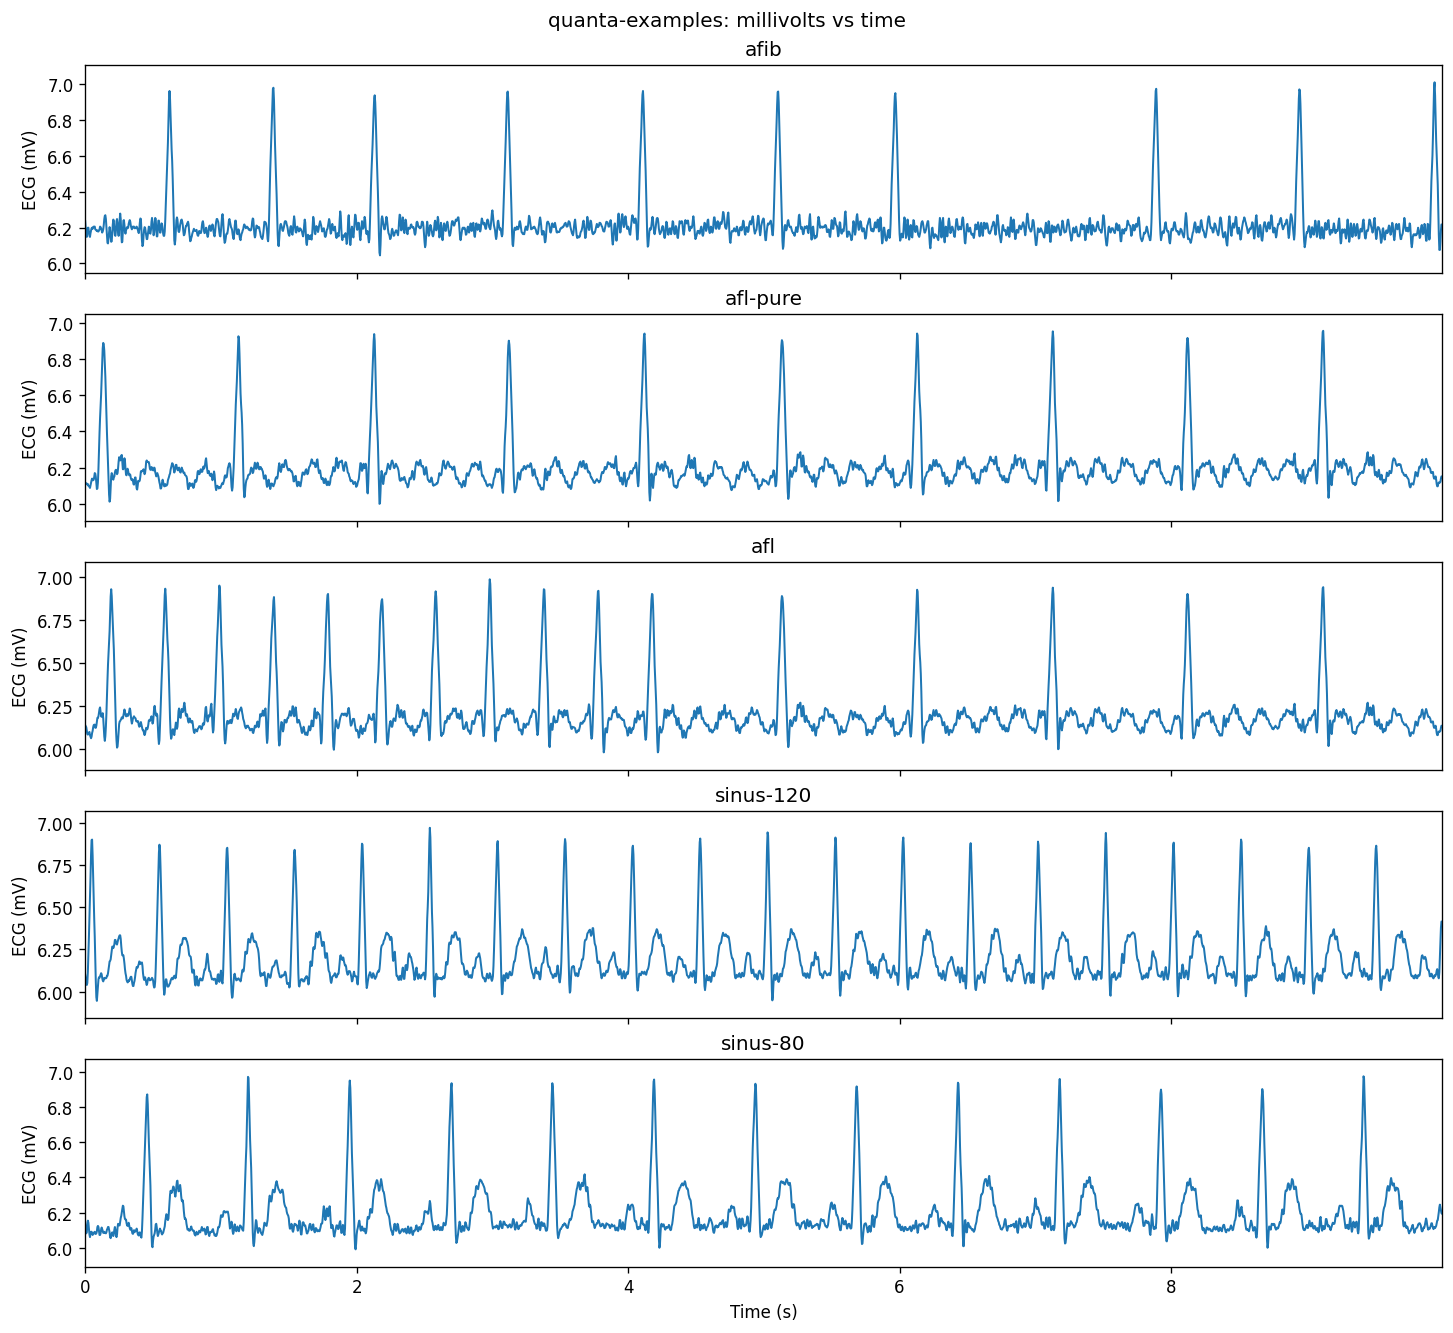

In [6]:
fig, axes = plt.subplots(
    len(names), 1, figsize=(12, 2.2 * len(names)),
    sharex=True, constrained_layout=True,
)
axes = np.atleast_1d(axes)
for ax, name in zip(axes, names):
    ax.plot(time_256hz_s, ecgs_mv[name], linewidth=1.2)
    ax.set_title(name)
    ax.set_ylabel("ECG (mV)")
    ax.margins(x=0, y=0.1)
axes[-1].set_xlabel("Time (s)")
fig.suptitle(f"{EXAMPLE_SET}: millivolts vs time")
plt.show()

## Round-trip back to raw ADC counts

Rounding the converted millivolt values back to ADC counts must recover every
original 256 Hz sample exactly.

In [7]:
round_trip_adc = {
    name: np.rint(ecg_mv / ADC_TO_MV).astype(np.uint16)
    for name, ecg_mv in ecgs_mv.items()
}
for name, original_adc in ecgs_adc_256hz.items():
    np.testing.assert_array_equal(
        round_trip_adc[name], original_adc,
        err_msg=f"{name}: ADC -> mV -> ADC did not recover the original samples",
    )
print(f"All {len(names)} examples round-trip from ADC -> mV -> ADC exactly.")

All 5 examples round-trip from ADC -> mV -> ADC exactly.


## Run TinyAF-S/M/L

Run each selected implementation on the original 256 Hz ADC arrays. Each
implementation performs its own ADC conversion and preprocessing; the plotted
millivolt arrays are not passed to an ADC API.

Default thresholds target 85% combined AFIB/AFL sensitivity on BWH-validation
and are read from the saved model metadata each time the prediction cell runs.
This also refreshes thresholds in an already-running kernel.


In [8]:
ecg_array = np.stack([ecgs_adc_256hz[name] for name in names])
rows = []
for model in MODELS:
    # Read on every run so an existing kernel picks up updated model metadata.
    metadata_path = MODEL_SPECS[model].metadata
    threshold = float(np.float32(json.loads(metadata_path.read_text())["threshold"]))
    for implementation in IMPLEMENTATIONS:
        print(f"Running {model}: {implementation}")
        if implementation == "python":
            probabilities = predict_python(
                ecg_array, model=model, sample_rate=TARGET_RATE_HZ,
                quanta_adc_to_physical=True,
            )
        else:
            probabilities = predict_c(
                ecg_array, model=model, threshold=threshold, mode=implementation,
            )
        for name, probability in zip(names, probabilities.reshape(-1)):
            probability = float(probability)
            prediction = (
                "No prediction" if not np.isfinite(probability)
                else "AF/AFL" if probability >= threshold
                else "Below threshold"
            )
            rows.append({
                "example": name,
                "model": model,
                "implementation": implementation,
                "probability": probability,
                "threshold": threshold,
                "prediction": prediction,
            })

results = pd.DataFrame(rows)
with pd.option_context("display.max_rows", None, "display.precision", 9):
    display(results.set_index(["example", "model", "implementation"]).round(
        {"probability": 6, "threshold": 9},
    ))

Running TINYAF-S: python
Running TINYAF-S: reference
cc -Ic_model -DMODEL_WEIGHTS_HEADER='"TINYAF_S_weights.h"' -DTINYAF_OPTIMIZED=0 -O3 -std=c99 -Wall -Wextra -Wpedantic -fno-fast-math -ffp-contract=off -DTINYAF_DIAGNOSTICS -fPIC -shared c_model/tinyaf.c -lm -o compile/reference/S/libtinyaf.so


cc -Ic_model -DMODEL_WEIGHTS_HEADER='"TINYAF_S_weights.h"' -DTINYAF_OPTIMIZED=0 -O3 -std=c99 -Wall -Wextra -Wpedantic -fno-fast-math -ffp-contract=off tinyaf_caller.c c_model/tinyaf.c -lm -o compile/reference/S/tinyaf_caller


Running TINYAF-S: optimized
make: Nothing to be done for 'all'.
Running TINYAF-M: python
Running TINYAF-M: reference
cc -Ic_model -DMODEL_WEIGHTS_HEADER='"TINYAF_M_weights.h"' -DTINYAF_OPTIMIZED=0 -O3 -std=c99 -Wall -Wextra -Wpedantic -fno-fast-math -ffp-contract=off -DTINYAF_DIAGNOSTICS -fPIC -shared c_model/tinyaf.c -lm -o compile/reference/M/libtinyaf.so


cc -Ic_model -DMODEL_WEIGHTS_HEADER='"TINYAF_M_weights.h"' -DTINYAF_OPTIMIZED=0 -O3 -std=c99 -Wall -Wextra -Wpedantic -fno-fast-math -ffp-contract=off tinyaf_caller.c c_model/tinyaf.c -lm -o compile/reference/M/tinyaf_caller


Running TINYAF-M: optimized
make: Nothing to be done for 'all'.
Running TINYAF-L: python
Running TINYAF-L: reference
cc -Ic_model -DMODEL_WEIGHTS_HEADER='"TINYAF_L_weights.h"' -DTINYAF_OPTIMIZED=0 -O3 -std=c99 -Wall -Wextra -Wpedantic -fno-fast-math -ffp-contract=off -DTINYAF_DIAGNOSTICS -fPIC -shared c_model/tinyaf.c -lm -o compile/reference/L/libtinyaf.so


cc -Ic_model -DMODEL_WEIGHTS_HEADER='"TINYAF_L_weights.h"' -DTINYAF_OPTIMIZED=0 -O3 -std=c99 -Wall -Wextra -Wpedantic -fno-fast-math -ffp-contract=off tinyaf_caller.c c_model/tinyaf.c -lm -o compile/reference/L/tinyaf_caller


Running TINYAF-L: optimized
make: Nothing to be done for 'all'.


,,,probability,threshold,prediction
example,model,implementation,,,
afib,TINYAF-S,python,0.743405,0.414806813,AF/AFL
afl-pure,TINYAF-S,python,0.478540,0.414806813,AF/AFL
afl,TINYAF-S,python,0.125985,0.414806813,Below threshold
sinus-120,TINYAF-S,python,0.008298,0.414806813,Below threshold
sinus-80,TINYAF-S,python,0.000830,0.414806813,Below threshold
afib,TINYAF-S,reference,0.743405,0.414806813,AF/AFL
afl-pure,TINYAF-S,reference,0.478540,0.414806813,AF/AFL
afl,TINYAF-S,reference,0.125985,0.414806813,Below threshold
sinus-120,TINYAF-S,reference,0.008298,0.414806813,Below threshold


## Compare implementations

Put the probabilities side by side for each example and model. When Python and C
are both selected, also show the absolute difference from Python. A missing
prediction is marked `NaN`.

In [9]:
comparison = results.pivot(
    index=["example", "model"], columns="implementation", values="probability",
).reindex(
    index=pd.MultiIndex.from_product([names, MODELS], names=["example", "model"]),
    columns=list(IMPLEMENTATIONS),
)
if "python" in IMPLEMENTATIONS:
    for implementation in IMPLEMENTATIONS:
        if implementation != "python":
            comparison[f"|{implementation} - python|"] = (
                comparison[implementation] - comparison["python"]
            ).abs()
with pd.option_context("display.max_rows", None):
    display(comparison.round(8))

implementation        python  reference  optimized  |reference - python|  \
example   model                                                            
afib      TINYAF-S  0.743405   0.743405   0.743398          6.000000e-08   
          TINYAF-M  0.338809   0.338809   0.338810          2.100000e-07   
          TINYAF-L  0.791706   0.791706   0.791698          1.200000e-07   
afl-pure  TINYAF-S  0.478540   0.478540   0.478543          3.000000e-08   
          TINYAF-M  0.493570   0.493570   0.493573          2.400000e-07   
          TINYAF-L  0.449060   0.449060   0.449063          0.000000e+00   
afl       TINYAF-S  0.125985   0.125985   0.125986          1.000000e-08   
          TINYAF-M  0.466302   0.466302   0.466304          6.000000e-08   
          TINYAF-L  0.817081   0.817081   0.817082          6.000000e-08   
sinus-120 TINYAF-S  0.008298   0.008298   0.008298          0.000000e+00   
          TINYAF-M  0.003704   0.003704   0.003704          0.000000e+00   
          TINYAF-L  0.004695   0.004695   0.004695          0.000000e+00   
sinus-80  TINYAF-S  0.000830   0.000830   0.000830          0.000000e+00   
          TINYAF-M  0.000579   0.000579   0.000579          0.000000e+00   
          TINYAF-L  0.000547   0.000547   0.000547          0.000000e+00   

implementation      |optimized - python|  
example   model                           
afib      TINYAF-S          6.910000e-06  
          TINYAF-M          6.000000e-07  
          TINYAF-L          8.640000e-06  
afl-pure  TINYAF-S          3.100000e-06  
          TINYAF-M          3.700000e-06  
          TINYAF-L          3.100000e-06  
afl       TINYAF-S          9.700000e-07  
          TINYAF-M          2.710000e-06  
          TINYAF-L          3.600000e-07  
sinus-120 TINYAF-S          1.600000e-07  
          TINYAF-M          6.000000e-08  
          TINYAF-L          3.000000e-08  
sinus-80  TINYAF-S          0.000000e+00  
          TINYAF-M          1.000000e-08  
          TINYAF-L          0.000000e+00